# Lab 08: Decision Trees, Random Forests and Costly Decisions

## Track A: Pima Diabetes Dataset

#**------------------------------------------------------------------------------**

### 1. Introduction

In this lab, we use the Pima Diabetes dataset to predict whether a patient has diabetes. We will explore the dataset, handle missing values, train machine learning models, compare their performance and study the cost of incorrect predictions.

In [30]:
import pandas as pd

# Load dataset
df = pd.read_csv('/content/pima_diabetes.csv')

# Display dataset
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


#**------------------------------------------------------------------------------**


## 2. Data Audit

In this step, we check the dataset for missing values, class balance and suspicious zero values. Some zero values represent measurements that were not recorded.

In [31]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Check class balance
print("\nClass Balance:")
print(df["Outcome"].value_counts())

print("\nDiabetes Percentage:")
print(df["Outcome"].value_counts(normalize=True).round(3))

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check suspicious zero values
hidden = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("\nZero Values:")
print((df[hidden] == 0).sum())

Dataset Shape: (768, 9)

Class Balance:
Outcome
0    500
1    268
Name: count, dtype: int64

Diabetes Percentage:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Missing Values:
Pregnancies         0
Glucose             0
BloodPressure       0
SkinThickness       0
Insulin             0
BMI                 0
DiabetesPedigree    0
Age                 0
Outcome             0
dtype: int64

Zero Values:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64



### 2.1 Handling Hidden Missing Values

Zero values in Glucose, BloodPressure, SkinThickness, Insulin and BMI are treated as missing values because these measurements cannot normally be zero. We replace these zeros with NaN so they can be handled during model training.

In [32]:
import numpy as np

# Replace impossible zeros with missing values
df[hidden] = df[hidden].replace(0, np.nan)

# Check missing values again
print("Missing Values After Replacement:")
print(df.isna().sum())

print("\nMissing Percentage:")
print(df.isna().mean().round(3))

Missing Values After Replacement:
Pregnancies           0
Glucose               5
BloodPressure        35
SkinThickness       227
Insulin             374
BMI                  11
DiabetesPedigree      0
Age                   0
Outcome               0
dtype: int64

Missing Percentage:
Pregnancies         0.000
Glucose             0.007
BloodPressure       0.046
SkinThickness       0.296
Insulin             0.487
BMI                 0.014
DiabetesPedigree    0.000
Age                 0.000
Outcome             0.000
dtype: float64


### Section 2 Summary: Data Audit

- The dataset contains **768 rows and 9 columns**.
- It has **500 patients without diabetes** and **268 patients with diabetes**.
- Five measurement columns contained suspicious zero values, so these were marked as missing.
- Insulin had the highest number of missing values (**374, or 48.7%**).

**Conclusion:** The data audit identified values that needed to be handled before model training. The missing values are handled by the imputer inside the model pipelines.

#**------------------------------------------------------------------------------**


## 3. Baseline and First Decision Tree

In this section, we split the dataset into training and testing data. First, we create a baseline model. Then, we train a Decision Tree Classifier and compare its performance with the baseline.

In [33]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns="Outcome")
y = df["Outcome"]

# Split data into training and testing sets
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print("Training Data:", Xtr.shape)
print("Testing Data:", Xte.shape)

Training Data: (576, 8)
Testing Data: (192, 8)


In [34]:
from sklearn.dummy import DummyClassifier

# Create baseline model
base = DummyClassifier(strategy="most_frequent")

# Train the model
base.fit(Xtr, ytr)

# Check accuracy
print("Baseline Accuracy:", round(base.score(Xte, yte), 3))

Baseline Accuracy: 0.651


In [35]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Create Decision Tree pipeline
tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(max_depth=3, random_state=42))
])

# Train the model
tree.fit(Xtr, ytr)

# Check accuracy
print("Decision Tree Accuracy:", round(tree.score(Xte, yte), 3))

Decision Tree Accuracy: 0.708


In [36]:
# Display decision tree rules
print(export_text(
    tree.named_steps["model"],
    feature_names=list(X.columns)
))

|--- Glucose <= 132.50
|   |--- Age <= 30.50
|   |   |--- BMI <= 45.40
|   |   |   |--- class: 0
|   |   |--- BMI >  45.40
|   |   |   |--- class: 1
|   |--- Age >  30.50
|   |   |--- BMI <= 26.90
|   |   |   |--- class: 0
|   |   |--- BMI >  26.90
|   |   |   |--- class: 0
|--- Glucose >  132.50
|   |--- Glucose <= 154.50
|   |   |--- BMI <= 29.95
|   |   |   |--- class: 0
|   |   |--- BMI >  29.95
|   |   |   |--- class: 1
|   |--- Glucose >  154.50
|   |   |--- Insulin <= 80.00
|   |   |   |--- class: 0
|   |   |--- Insulin >  80.00
|   |   |   |--- class: 1




### 3.1 Understanding the Decision Tree

A Decision Tree makes predictions by asking a series of questions about the input features. It divides patients into groups based on their medical measurements. The final result predicts whether a patient has diabetes or not.

In [37]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Test different tree depths
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]

print("Depth | Train Accuracy | Test Accuracy | CV Accuracy")

for d in depths:

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeClassifier(max_depth=d, random_state=42))
    ])

    # Cross-validation
    cv = cross_val_score(model, Xtr, ytr, cv=5).mean()

    # Train model
    model.fit(Xtr, ytr)

    # Calculate accuracy
    train = model.score(Xtr, ytr)
    test = model.score(Xte, yte)

    print(d, "|", round(train, 3), "|", round(test, 3), "|", round(cv, 3))


Depth | Train Accuracy | Test Accuracy | CV Accuracy
1 | 0.757 | 0.682 | 0.747
2 | 0.76 | 0.708 | 0.745
3 | 0.792 | 0.708 | 0.743
4 | 0.826 | 0.75 | 0.726
5 | 0.847 | 0.75 | 0.726
6 | 0.882 | 0.75 | 0.722
8 | 0.927 | 0.75 | 0.687
10 | 0.972 | 0.745 | 0.714
None | 1.0 | 0.688 | 0.693


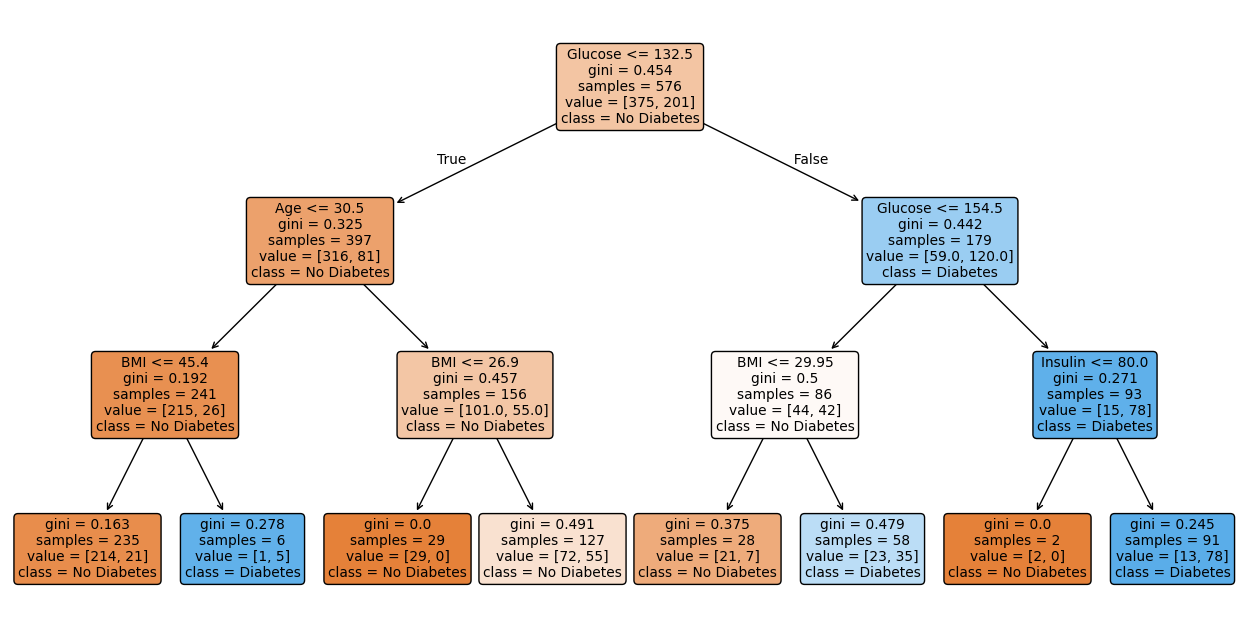

In [38]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    tree.named_steps["model"],
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True
)

plt.show()



### 3.2 Overfitting Analysis Graph

This graph compares training accuracy and cross-validation accuracy at different tree depths. It helps us understand how a complex tree can memorize training data and perform poorly on unseen data.

Depth 3 was selected for an interpretable tree because its cross-validation accuracy (0.743) is close to the best score (0.747 at depth 1), while providing more decision detail. As tree depth increases, training accuracy rises, but cross-validation accuracy generally decreases. The unrestricted tree reaches 1.000 training accuracy but only 0.693 cross-validation accuracy, showing overfitting.

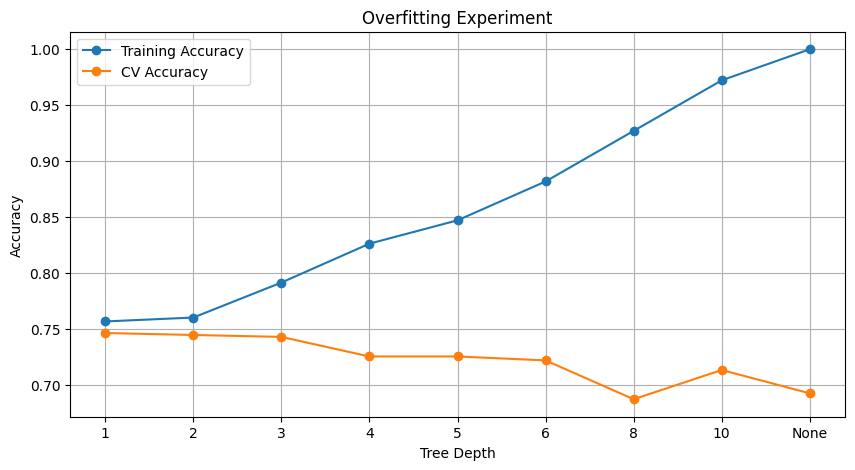

In [39]:
# Store accuracy for different tree depths
train_scores = []
cv_scores = []

for d in depths:
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeClassifier(max_depth=d, random_state=42))
    ])

    train_scores.append(model.fit(Xtr, ytr).score(Xtr, ytr))
    cv_scores.append(cross_val_score(model, Xtr, ytr, cv=5).mean())

# Draw graph
plt.figure(figsize=(10, 5))
plt.plot(range(len(depths)), train_scores, marker="o", label="Training Accuracy")
plt.plot(range(len(depths)), cv_scores, marker="o", label="CV Accuracy")

plt.xticks(range(len(depths)), [str(d) for d in depths])
plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title("Overfitting Experiment")
plt.legend()
plt.grid()
plt.show()

### Section 3 Summary: Baseline and Decision Tree

- The data was divided into **576 training records** and **192 testing records**.
- The baseline model achieved **0.651 accuracy**.
- The Decision Tree achieved **0.708 test accuracy**, which is higher than the baseline.
- Depth 3 was selected for an interpretable tree. Its cross-validation accuracy was **0.743**.
- The unrestricted tree reached **1.000 training accuracy** but only **0.693 cross-validation accuracy**, showing overfitting.

**Conclusion:** The Decision Tree performed better than the baseline. Limiting tree depth helps control overfitting and keeps the model easier to understand.

#**------------------------------------------------------------------------------**


## 4. Random Forest and Model Comparison

In this section, we compare Decision Trees and Random Forest using ROC-AUC. Random Forest combines multiple decision trees to improve prediction performance and stability.

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

In [41]:
# Train Random Forest
rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

rf.fit(Xtr, ytr)

# Predict diabetes probabilities
p = rf.predict_proba(Xte)[:, 1]

print("Test Accuracy:", round(rf.score(Xte, yte), 3))
print("Test ROC-AUC:", round(roc_auc_score(yte, p), 3))


Test Accuracy: 0.755
Test ROC-AUC: 0.811


In [42]:
# Create four models
models = {
    "Baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),

        ("model", DummyClassifier(strategy="most_frequent"))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=3, random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=3,
            random_state=42
        ))
    ]),

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ])
}

# Five-fold cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_val_score(
        model, X, y, cv=skf, scoring="roc_auc"
    )

    print(name)
    print("Mean ROC-AUC:", round(scores.mean(), 3))
    print("Standard Deviation:", round(scores.std(), 3))
    print()

Baseline
Mean ROC-AUC: 0.5
Standard Deviation: 0.0

Decision Tree
Mean ROC-AUC: 0.788
Standard Deviation: 0.044

Random Forest
Mean ROC-AUC: 0.836
Standard Deviation: 0.018

Logistic Regression
Mean ROC-AUC: 0.837
Standard Deviation: 0.02



### Section 4 Summary: Model Comparison

The 5-fold cross-validation ROC-AUC results were:

- Baseline: **0.500 ± 0.000**
- Decision Tree: **0.788 ± 0.044**
- Random Forest: **0.836 ± 0.018**
- Logistic Regression: **0.837 ± 0.020**

The Random Forest test accuracy was **0.755**. Logistic Regression had the highest mean ROC-AUC (**0.837**), while Random Forest was very close (**0.836**).

**Conclusion:** Random Forest and Logistic Regression performed similarly and both outperformed the Decision Tree and baseline in cross-validation ROC-AUC. Logistic Regression had the slightly higher mean score in this comparison.

#**------------------------------------------------------------------------------**


## 5. Feature Importance

In this section, we examine which features are important for the Random Forest model. We use Gini Importance and Permutation Importance to understand how the model makes predictions.

In [43]:
from sklearn.inspection import permutation_importance

# Gini importance
gini = pd.Series(
    rf.named_steps["model"].feature_importances_,
    index=X.columns
)

# Permutation importance
perm = permutation_importance(
    rf, Xte, yte,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc"
)

permutation = pd.Series(
    perm.importances_mean,
    index=X.columns
)

# Compare both importances
importance = pd.DataFrame({
    "Gini": gini,
    "Permutation": permutation
})

print(importance.round(3).sort_values("Gini", ascending=False))


                   Gini  Permutation
Glucose           0.313        0.111
BMI               0.167        0.044
Age               0.123        0.024
DiabetesPedigree  0.107        0.005
Pregnancies       0.083        0.009
Insulin           0.083        0.001
BloodPressure     0.066       -0.002
SkinThickness     0.057       -0.000


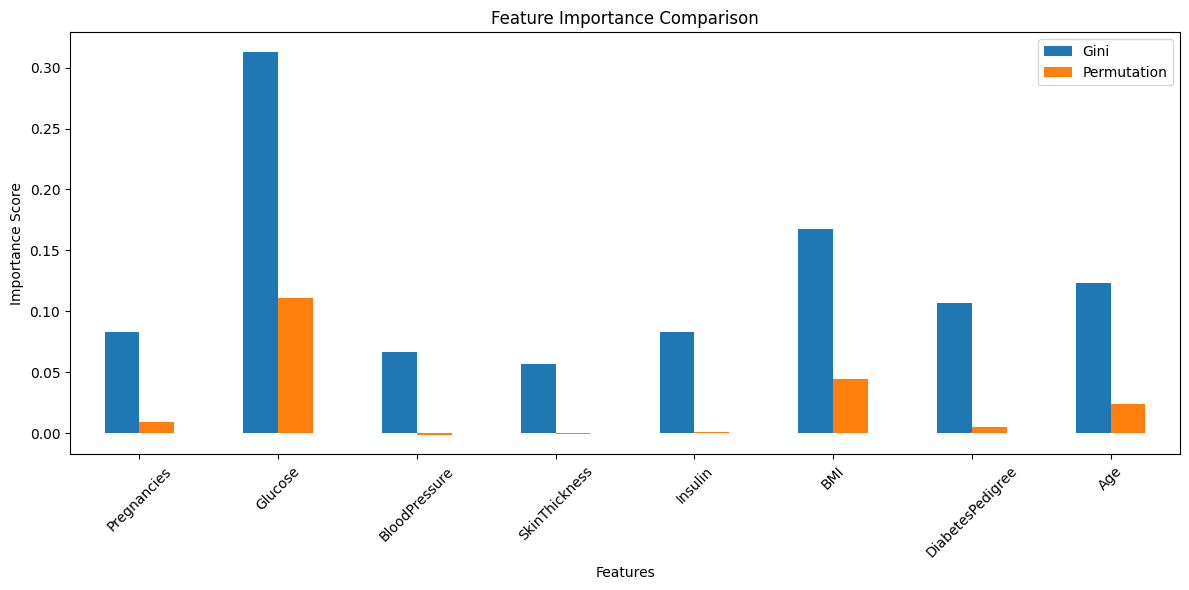

In [44]:
importance.plot(kind="bar", figsize=(12, 6))

plt.title("Feature Importance Comparison")
plt.ylabel("Importance Score")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 5.1 Understanding Feature Importance

Gini Importance shows how much each feature helps the Random Forest make decisions. Permutation Importance shows how much model performance decreases when a feature is shuffled.

Both methods help us understand which medical measurements are important. Their rankings may differ because they use different methods of calculation. Feature importance shows model reliance, but it does not prove that a feature causes diabetes.

Glucose, BMI and Age rank highly in both Gini and Permutation Importance. However, Insulin has a Gini importance of 0.083 but a Permutation Importance of only 0.001. This shows that the two methods can give different importance rankings.

In [45]:
# Compare feature rankings
print("Gini Importance Ranking:")
print(gini.sort_values(ascending=False).round(3))

print("\nPermutation Importance Ranking:")
print(permutation.sort_values(ascending=False).round(3))

Gini Importance Ranking:
Glucose             0.313
BMI                 0.167
Age                 0.123
DiabetesPedigree    0.107
Insulin             0.083
Pregnancies         0.083
BloodPressure       0.066
SkinThickness       0.057
dtype: float64

Permutation Importance Ranking:
Glucose             0.111
BMI                 0.044
Age                 0.024
Pregnancies         0.009
DiabetesPedigree    0.005
Insulin             0.001
SkinThickness      -0.000
BloodPressure      -0.002
dtype: float64


### Section 5 Summary: Feature Importance

- **Glucose, BMI and Age** ranked highly in both importance methods.
- Glucose had the highest Gini importance (**0.313**) and permutation importance (**0.111**).
- Insulin had Gini importance of **0.083**, but permutation importance of only **0.001**.
- The rankings differ because Gini and permutation importance measure feature importance in different ways.

**Conclusion:** The model relied strongly on Glucose, BMI and Age in this experiment. Feature importance describes how the model uses features; it does not prove that a feature causes diabetes.

#**------------------------------------------------------------------------------**


## 6. Decision Threshold and Cost Analysis

A missed diabetic patient is considered three times more costly than a false alarm. We compare different decision thresholds to find the threshold that gives the lowest total cost.

In [46]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score

# Cost of incorrect predictions
COST_FN = 3
COST_FP = 1

# Check different thresholds
thresholds = [0.5, 0.4, 0.3, 0.225, 0.2]

print("Threshold | Recall | Precision | FN | FP | Total Cost")

for t in thresholds:
    pred = (p >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()

    cost = COST_FN * fn + COST_FP * fp

    print(t, "|",
          round(recall_score(yte, pred), 3), "|",
          round(precision_score(yte, pred, zero_division=0), 3), "|",
          fn, "|", fp, "|", cost)


Threshold | Recall | Precision | FN | FP | Total Cost
0.5 | 0.567 | 0.679 | 29 | 18 | 105
0.4 | 0.642 | 0.597 | 24 | 29 | 101
0.3 | 0.806 | 0.568 | 13 | 41 | 80
0.225 | 0.866 | 0.558 | 9 | 46 | 73
0.2 | 0.881 | 0.522 | 8 | 54 | 78


In [47]:
# Test many thresholds
grid = np.arange(0.05, 0.9, 0.025)

costs = []

for t in grid:
    pred = (p >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()

    cost = COST_FN * fn + COST_FP * fp
    costs.append(cost)

# Find minimum cost
best_threshold = grid[np.argmin(costs)]

print("Best Threshold:", round(best_threshold, 3))
print("Minimum Cost:", min(costs))

Best Threshold: 0.225
Minimum Cost: 73


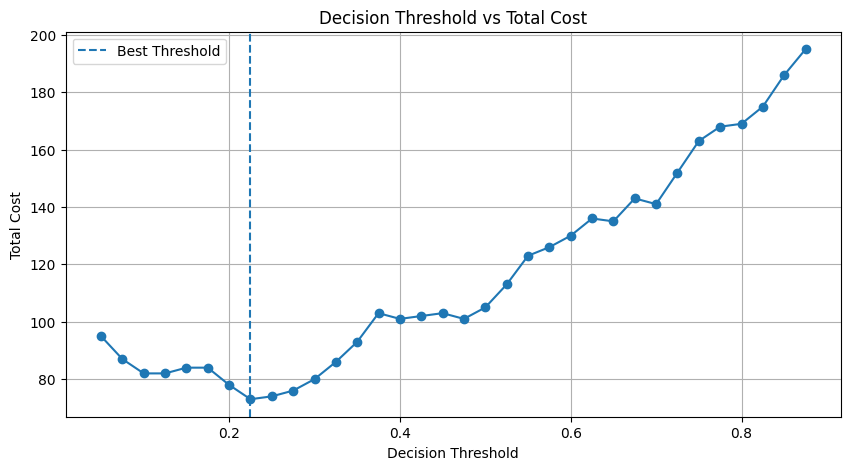

In [48]:
plt.figure(figsize=(10, 5))

plt.plot(grid, costs, marker="o")

plt.axvline(best_threshold, linestyle="--", label="Best Threshold")

plt.title("Decision Threshold vs Total Cost")
plt.xlabel("Decision Threshold")
plt.ylabel("Total Cost")

plt.legend()
plt.grid()
plt.show()

In [49]:
# Now a missed patient costs 6 instead of 3
COST_FN = 6
COST_FP = 1

new_costs = []

for t in grid:
    pred = (p >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()

    new_costs.append(COST_FN * fn + COST_FP * fp)

new_best = grid[np.argmin(new_costs)]

print("Best Threshold (FN cost = 6):", round(new_best, 3))
print("Minimum Cost:", min(new_costs))

Best Threshold (FN cost = 6): 0.1
Minimum Cost: 88


### Section 6 Summary: Decision Threshold and Cost Analysis

When a false negative costs **3 units** and a false positive costs **1 unit**:

- Threshold **0.5** gave a total cost of **105**.
- Threshold **0.225** gave the lowest tested cost of **73**.
- At 0.225, false negatives decreased from **29 to 9**, while false positives increased from **18 to 46**.

When the false-negative cost doubled to **6 units**, the selected threshold changed to **0.1**, with a total cost of **88**.

**Conclusion:** A lower threshold identifies more possible diabetic patients but also creates more false alarms. The best threshold depends on the relative cost of each type of error.

#**------------------------------------------------------------------------------**


## 7. Decision Memo

The clinic wants to identify patients who may have diabetes and need further testing.

A false negative means a diabetic patient is missed. A false positive means a healthy patient is sent for an unnecessary test.

We assume that a false negative costs 3 units and a false positive costs 1 unit. We compare the default threshold of 0.5 with the threshold that gives the lowest total cost.


In [50]:
# Compare default and selected thresholds
for t in [0.5, float(best_threshold)]:

    pred = (p >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()

    print("\nThreshold:", round(t, 3))
    print("Recall:", round(recall_score(yte, pred), 3))
    print("Precision:", round(precision_score(yte, pred, zero_division=0), 3))
    print("False Negatives:", fn)
    print("False Positives:", fp)
    print("Total Cost:", 3 * fn + fp)


Threshold: 0.5
Recall: 0.567
Precision: 0.679
False Negatives: 29
False Positives: 18
Total Cost: 105

Threshold: 0.225
Recall: 0.866
Precision: 0.558
False Negatives: 9
False Positives: 46
Total Cost: 73


In [51]:
# Compare the selected threshold when FN cost doubles
pred = (p >= new_best).astype(int)

tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()

print("When False Negative Cost = 6")
print("Selected Threshold:", round(new_best, 3))
print("Recall:", round(recall_score(yte, pred), 3))
print("Precision:", round(precision_score(yte, pred, zero_division=0), 3))
print("False Negatives:", fn)
print("False Positives:", fp)
print("Total Cost:", 6 * fn + fp)

When False Negative Cost = 6
Selected Threshold: 0.1
Recall: 0.97
Precision: 0.461
False Negatives: 2
False Positives: 76
Total Cost: 88


### Final Recommendation

I recommend using a threshold of **0.225** when the cost of a false negative is three times the cost of a false positive. At the default threshold of 0.5, the model misses 29 diabetic patients and produces 18 false alarms, with a total cost of 105. At threshold 0.225, it misses only 9 patients and produces 46 false alarms, reducing the total cost to 73. This means 20 fewer missed patients and 28 more false alarms. If the cost of a false negative doubles, the best threshold shifts to 0.1. This is an experimental model and should not be used as a medical diagnosis.

The threshold was selected and evaluated using the same test set, so its estimated cost may be optimistic. It should be validated on separate data.

#**------------------------------------------------------------------------------**

### Overall Project Conclusion

In this lab, we audited the Pima Diabetes dataset, handled suspicious zero values as missing data, trained and compared machine learning models, examined feature importance, and studied decision thresholds using different error costs.

The cross-validation results showed that Random Forest (**0.836 ± 0.018**) and Logistic Regression (**0.837 ± 0.020**) performed similarly. In the cost analysis, threshold **0.225** gave the lowest tested cost when a false negative cost three times as much as a false positive. When the false-negative cost doubled, the selected threshold changed to **0.1**.

**Final note:** These results are from an educational experiment. The threshold was selected and evaluated on the same test set, so its estimated cost may be optimistic. The model requires validation on separate data and must not be used as a medical diagnosis.